In [1]:
#imports:

import numpy as np
import matplotlib.pyplot as plt
import random
import os
from scipy.signal import find_peaks

#functions from ransac_pf.py: 
from ransac_pf import *

---File stats:
size: 1024
---File stats:
size: 1023


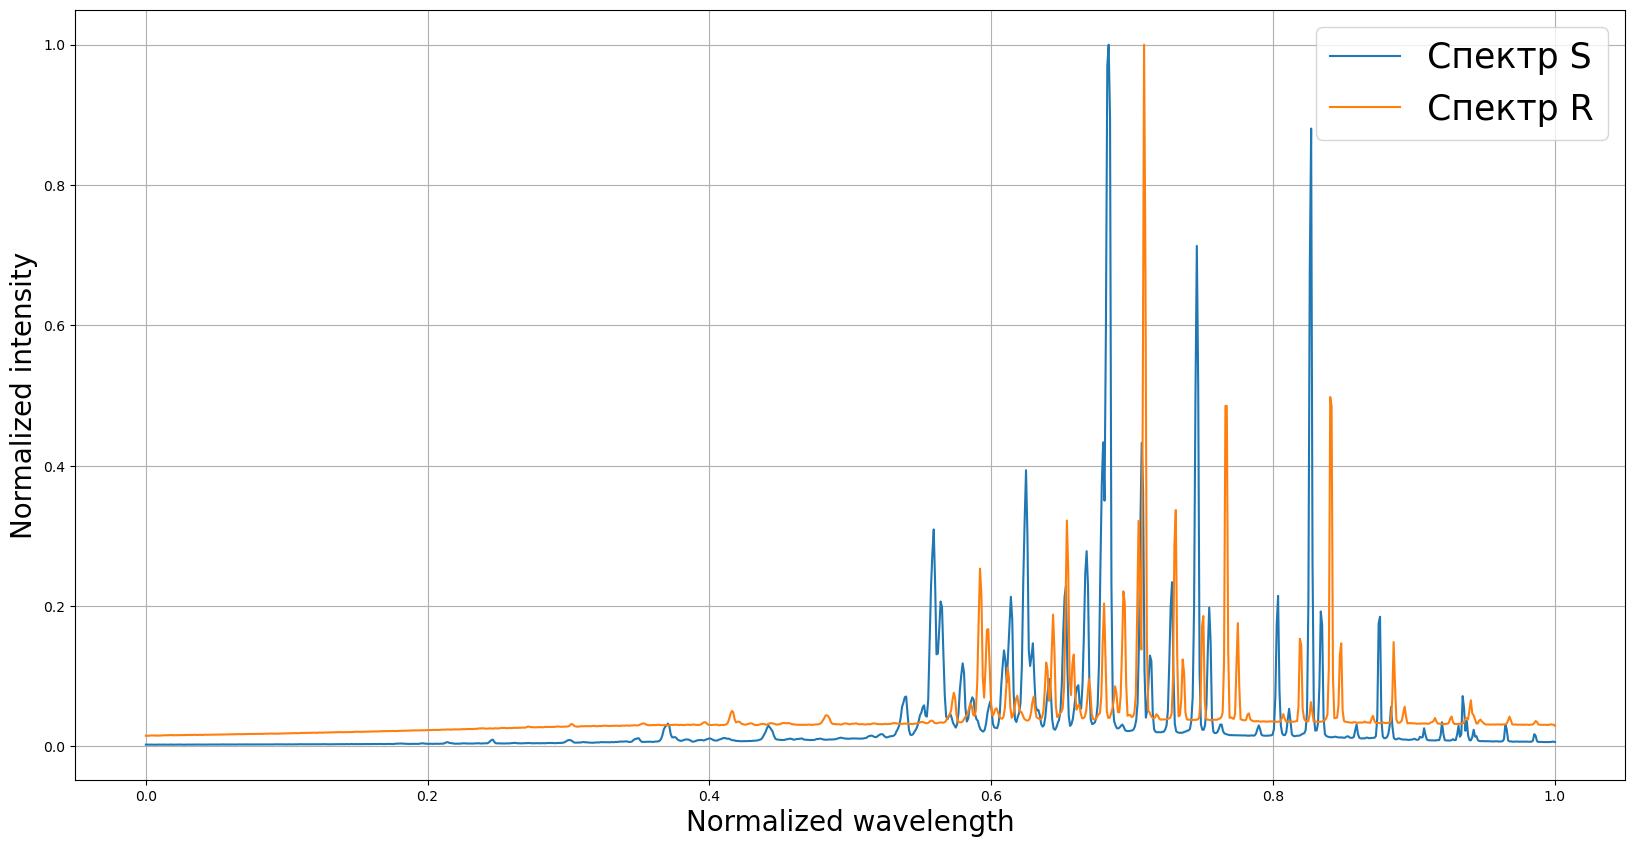

In [2]:
## --- Load image and calib
#loading image:
img = load_spectrum_data_txt('Lamp_3s_19Aur_360_5s_1D_3.txt')
img = normalize(img)
#loading data: (calib)
data  = load_spectrum_data_txt('lamp_calib')
data = normalize(data)
fig=plt.figure(figsize=(20,10))
ax=fig.add_subplot()
ax.grid()
ax.set_ylabel('Normalized intensity', fontsize=20)
ax.set_xlabel('Normalized wavelength', fontsize=20)
ax.plot(img[:,0],img[:,1],label='Спектр S')
ax.plot(data[:,0],data[:,1], label = 'Спектр R')
ax.legend(fontsize=25)

Length: 1023 1023
Polynomial coefficients (highest degree first, pixel to wavelength mapping):
[-0.01936779  0.02949857  0.92010835  0.07210239]


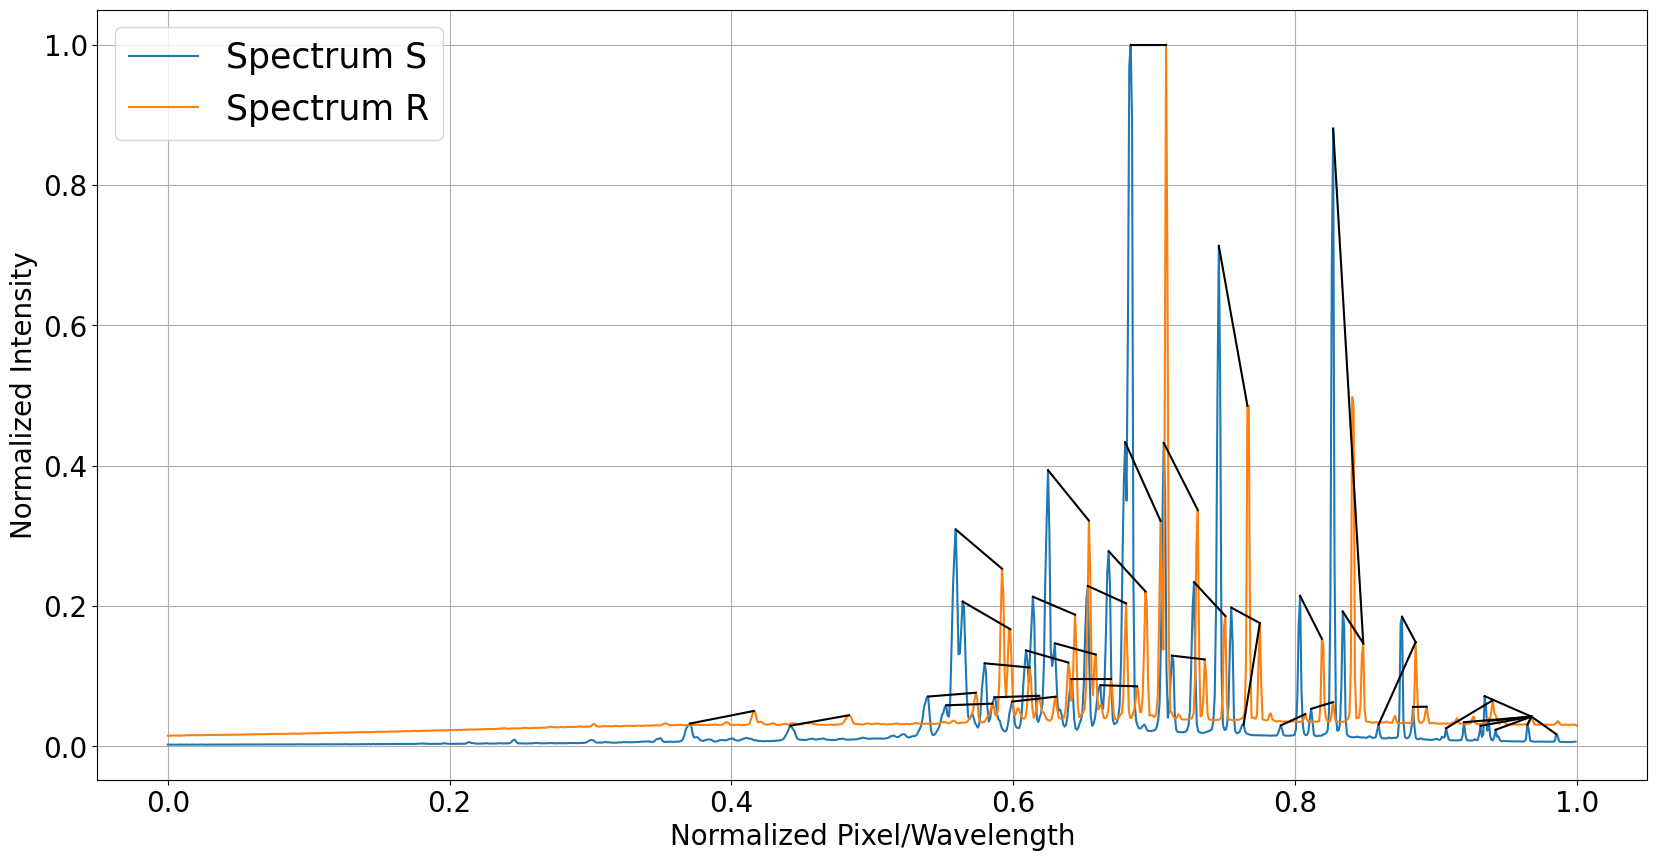

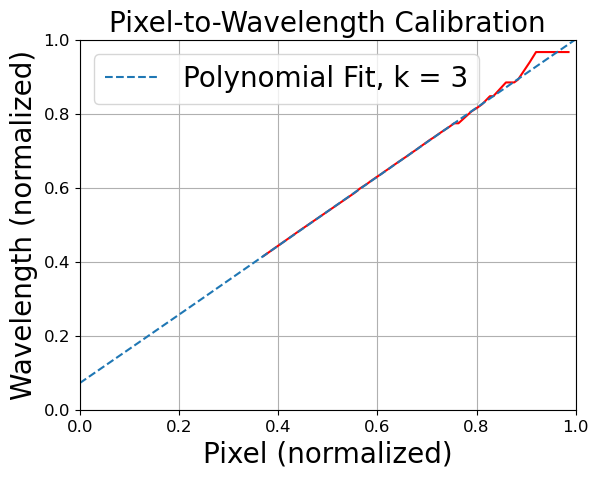

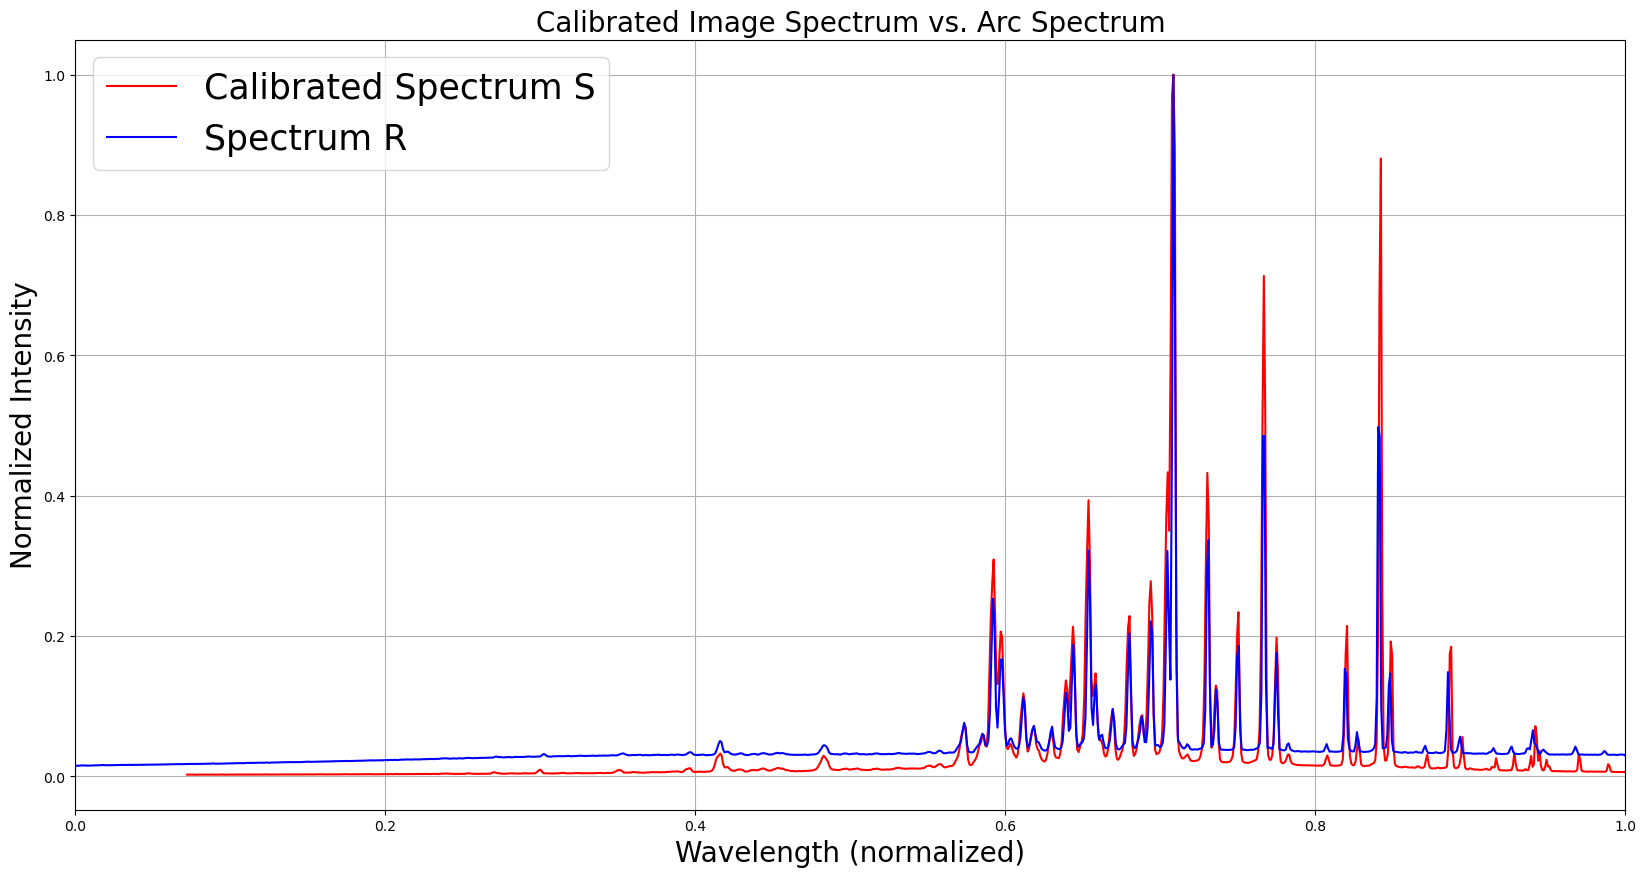

In [3]:
###DTW USE CASE:
arc = data
from dtw import peak
from dtw import dtw_distance
if len(img)>len(arc):
    img=img[:len(arc),:]
print('Length:',len(img),len(arc))
prominence = 0.01
peaks_img, _ = find_peaks(img[:, 1], prominence=prominence)
peaks_arc, _ = find_peaks(arc[:, 1], prominence=prominence)
##Peaks finded
# Plot initial spectra
fig = plt.figure(figsize=(20, 10))
ax = fig.add_subplot()
ax.grid()
ax.set_ylabel('Normalized Intensity', fontsize=20)
ax.set_xlabel('Normalized Pixel/Wavelength', fontsize=20)
ax.plot(img[:,0], img[:,1], label='Spectrum S')
ax.plot(arc[:,0], arc[:,1], label='Spectrum R')
ax.legend(fontsize=25)
# ax.set_title('Image and Arc Spectra with Matched Peaks')
ax.tick_params(axis='both',labelsize=20)
##Creating peak - type objects:
P_img = [peak(p, img[p, 0]) for p in peaks_img]
P_arc = [peak(p, arc[p, 0]) for p in peaks_arc]

##Selecting peaks local windows
local_window_size = 45
i=0
for p in P_img:
    i_start = int(p.index-local_window_size/2)
    i_end = int(p.index + local_window_size/2)
    if i_end>len(img)-1:
        i_end=len(img)
    p.local_window = img[i_start:i_end,:]
    p.normalize_local_window()
    
for p in P_arc:
    i_start = int(p.index-local_window_size/2)
    i_end = int(p.index + local_window_size/2)
    if i_end>len(img)-1:
        i_end=len(img)
    p.local_window = arc[i_start:i_end,:]
    p.normalize_local_window()
    
    
    
##Comparing:
for p in P_img:
    p.compare_to(P_arc,similarity_type='gaussian')
    x1 = img[p.index,0]
    y1 = img[p.index,1]
    x2 = arc[p.matched_index,0]
    y2 = arc[p.matched_index,1]
    ax.plot([x1,x2],[y1,y2],color ='k')
fig.savefig('dtw_matched_peaks.png',bbox_inches='tight')

fig2 = plt.figure()
ax2 = fig2.add_subplot()
pxl = []
wvlngth = []
for p in P_img:
    if p.matched_index != -1:
        pxl.append(img[p.index, 0])
        wvlngth.append(arc[p.matched_index, 0])
ax2.plot(pxl, wvlngth, 'r-')
ax2.grid()
ax2.set_xlabel('Pixel (normalized)', fontsize=20)
ax2.set_ylabel('Wavelength (normalized)', fontsize=20)
ax2.set_title('Pixel-to-Wavelength Calibration', fontsize=20)
ax2.set_ylim(0, 1)
ax2.set_xlim(0, 1)
ax2.tick_params(axis='both',labelsize=12)
# Polynomial fitting
degree = 3
if len(pxl) >= degree + 1:
    coeffs = np.polyfit(pxl[:-25], wvlngth[:-25], degree)
    poly = np.poly1d(coeffs)
    ax2.plot(img[:, 0], poly(img[:, 0]), '--', label='Polynomial Fit, k = 3')
    ax2.legend(fontsize=20, loc = 'upper left')
    print("Polynomial coefficients (highest degree first, pixel to wavelength mapping):")
    print(coeffs)
else:
    print("Not enough matched peaks for polynomial fitting.")
fig2.savefig('fit_DTW.png',bbox_inches='tight')
# Calibrated spectrum
fig3 = plt.figure(figsize=(20, 10))
ax3 = fig3.add_subplot()
if len(pxl) >= degree + 1:
    ax3.plot(poly(img[:, 0]), img[:, 1], c='r', label='Calibrated Spectrum S')
ax3.plot(arc[:, 0], arc[:, 1], c='b', label='Spectrum R')
ax3.legend(fontsize=25)
ax3.grid()
ax3.set_xlim(0, 1)
ax3.set_xlabel('Wavelength (normalized)', fontsize=20)
ax3.set_ylabel('Normalized Intensity', fontsize=20)
ax3.set_title('Calibrated Image Spectrum vs. Arc Spectrum', fontsize=20)
# fig3.savefig('calibrated_DTW.png',bbox_inches='tight')
plt.show()

In [4]:
### RANSAC_FP use case:
reference_peaks = []
image_peaks = []

#first find peaks and then append them into a list containing objects of peak_object type
peaks_img, _ = find_peaks(img[:, 1], prominence=prominence)
peaks_arc, _ = find_peaks(arc[:, 1], prominence=prominence)
for i in range(len(peaks_img)):
    image_peaks.append(peak_object(peak_type='measure', peak_id=peaks_img[i], peak_num=i,peak_pixel=img[peaks_img[i], 0],height = img[peaks_img[i],1]))
for i in range(len(peaks_arc)):
    reference_peaks.append(peak_object(peak_type='reference', peak_id=peaks_arc[i], peak_num=i,peak_wv=arc[peaks_arc[i], 0], height = arc[peaks_arc[i],1]))

41
36
Pair list: 41


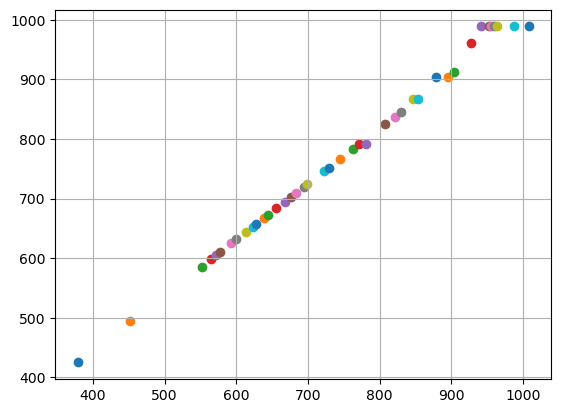

In [5]:
# Create pair list
pair_list = []
print(len(image_peaks))
print(len(P_arc))
for p in P_img:
    pair1 = None
    pair2 = None
    for pimg in image_peaks:
        if int(p.index)==int(pimg.peak_id):
            pair1 = pimg
    for pref in reference_peaks:
        if int(p.matched_index)==int(pref.peak_id):
            pair2 = pref
    if (pair1 is not None) and (pair2 is not None):
        pair_list.append([pair1,pair2])
print('Pair list:', len(pair_list))
fig=plt.figure()
ax=fig.add_subplot()
for pair in pair_list:
    ax.scatter(pair[0].peak_id, pair[1].peak_id)
ax.grid()

New max: 8 At  0 41
New max: 14 At  1 41
New max: 16 At  2 41
New max: 23 At  7 41
New max: 24 At  8 41
New max: 27 At  26 41
New max: 31 At  51 41
New max: 34 At  141 41


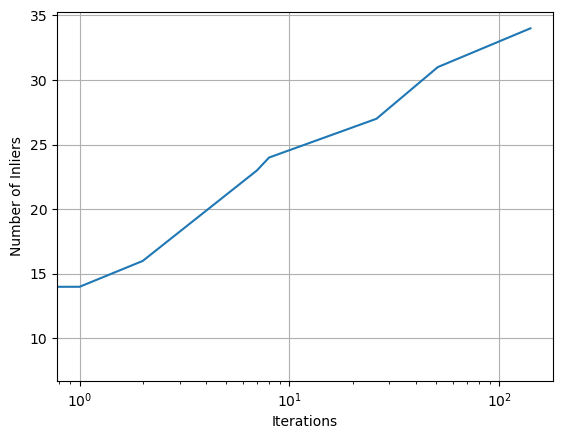

In [6]:
#### main loop and stuff : 



best_coeffs = None
best_inliers = None


#this parameters are variables.
## for the image and reference provided 
## this values of iter_max , polyorder and tolerance reach inlier count
## platoue at iter = 10^3 (the behaviour is random (as it should be)
## though)
iter_max = 3000
polyorder_k=3
tolerance = 1/1024

max_inliers = 0
ITER_LIST = []
ITER_LIST2 = []
MAX_IN_LIST = []
AVG_ERROR = []
STD_ERROR = []

for iter_num in range(iter_max):
    ##We select random pairs as anchors
    random_pairs_num = unique_random_sorted(5, len(pair_list)-1)
    maybeInliers_ref = []
    maybeInliers_img = []
    for rpn in random_pairs_num:
        pair = pair_list[rpn]
        maybeInliers_ref.append(pair[1])
        maybeInliers_img.append(pair[0])
    coeffs = find_fit(maybeInliers_ref,maybeInliers_img,polyorder_k)
    poly = np.poly1d(coeffs)
    c_inliers = []
    num_inliers = 0
    for pimg in image_peaks:
        pimg.maybe_wv = poly(pimg.peak_pixel)
    for pimg in image_peaks:
        for pref in reference_peaks:
            if np.abs(pimg.maybe_wv-pref.peak_wv)<=tolerance:
                num_inliers+=1
                c_inliers.append([pimg,pref])
    ##
    error=[]
    for inliers in c_inliers:
        pimg,pref = inliers
        x=[poly(pimg.peak_pixel),pref.peak_wv]
        y=[pimg.height,pref.height]
        error.append(np.abs(pref.peak_wv-poly(pimg.peak_pixel)))
    error=np.array(error)*4753.2548494585 #this magic number is normalization constant I printed earlier.
    AVG_ERROR.append(np.average(error))
    STD_ERROR.append(np.std(error))
    ITER_LIST2.append(iter_num)
    ##
    if num_inliers>max_inliers:
        max_inliers=num_inliers
        best_coeffs = coeffs
        best_inliers = c_inliers
        print('New max:',max_inliers, 'At ',iter_num, len(pair_list))
        ITER_LIST.append(iter_num)
        MAX_IN_LIST.append(max_inliers)
fig=plt.figure()
ax=fig.add_subplot()
ax.plot(ITER_LIST,MAX_IN_LIST)
ax.set_xscale('log')
ax.set_xlabel('Iterations')
ax.set_ylabel('Number of Inliers')
ax.grid()

Text(0.5, 0, 'Pixel (normalized)')

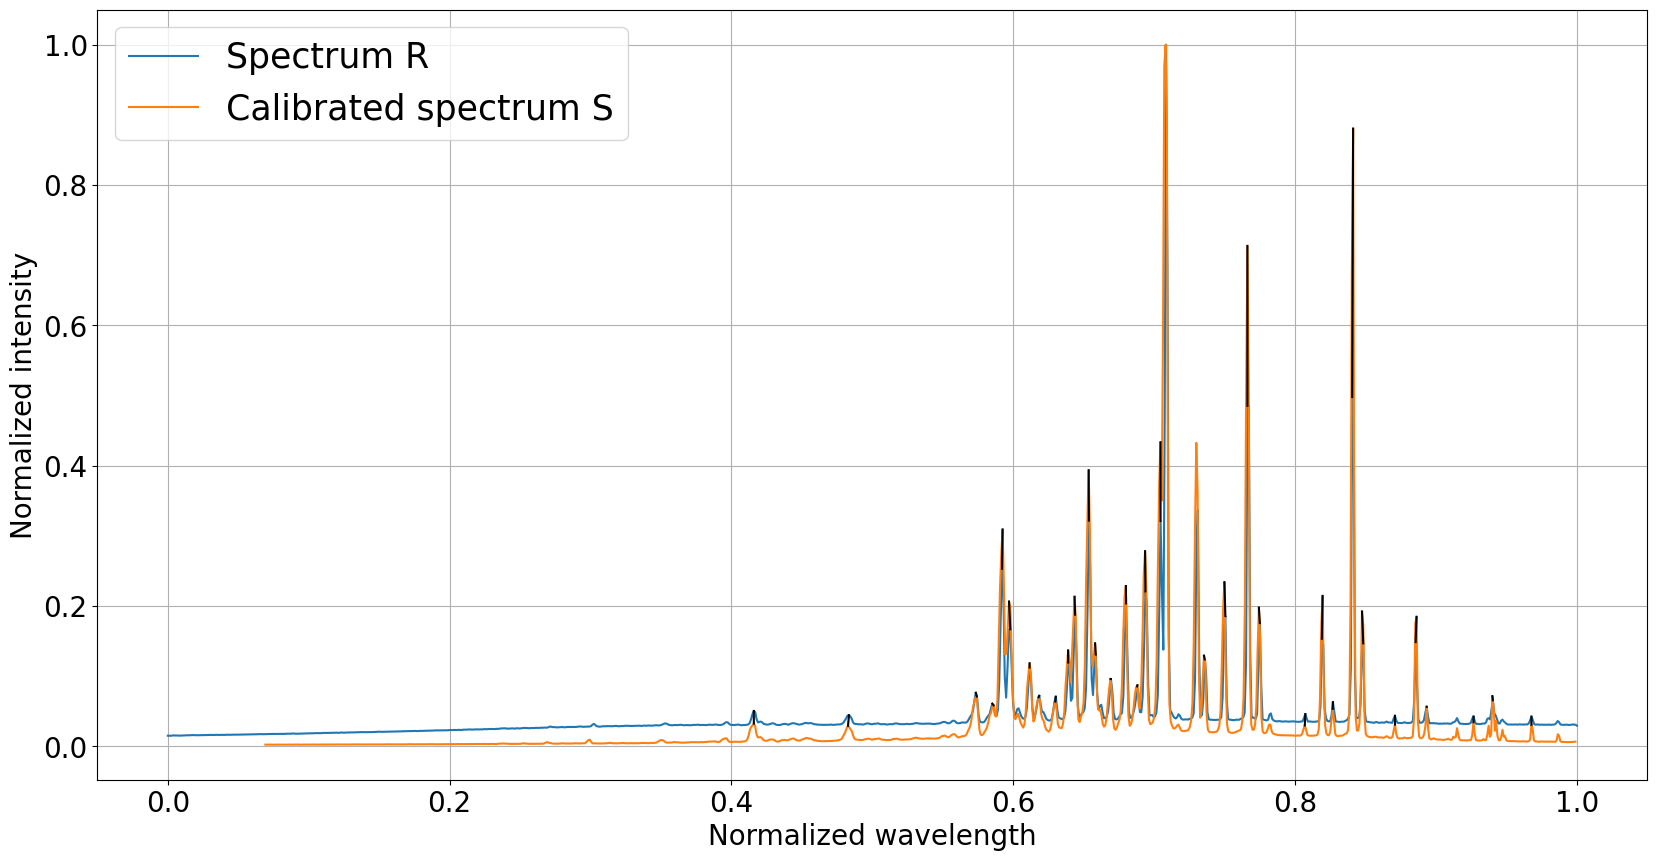

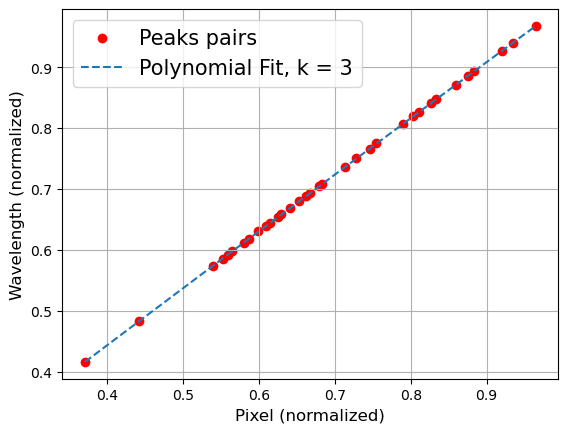

In [7]:
### Now with the obtained results we want
### fancy figure

poly = np.poly1d(best_coeffs)
fig=plt.figure(figsize=(20,10))
ax=fig.add_subplot()
ax.plot(arc[:,0],arc[:,1],label = 'Spectrum R')
ax.plot(poly(img[:,0]),img[:,1],label = 'Calibrated spectrum S')
ax.set_ylabel('Normalized intensity', fontsize=20)
ax.set_xlabel('Normalized wavelength', fontsize=20)
ax.tick_params(axis='both',labelsize=20)


### ransac formed some set of good peak pairs and to connect them with
### nice looking black solid lines we do this:
error=[]
for inliers in best_inliers:
    pimg,pref = inliers
    x=[poly(pimg.peak_pixel),pref.peak_wv]
    y=[pimg.height,pref.height]
    error.append(np.abs(pref.peak_wv-poly(pimg.peak_pixel)))
#     if(error[-1]>0.5):
#         ax.axvline(poly(pimg.peak_pixel))
    ax.plot(x,y,'k')
ax.legend(fontsize=25)
ax.grid()
### also to show the pixel - wv dependence and polynom we do this:

fig3 = plt.figure()
ax3=fig3.add_subplot()
X=[]
Y=[]
counter_1 = 0
for inliers in best_inliers:
    pimg,pref = inliers
    x= pimg.peak_pixel
    y = pref.peak_wv
    X.append(x)
    Y.append(y)
    if counter_1==0:
        ax3.scatter(x,y,c='r', label = 'Peaks pairs')
    else:
        ax3.scatter(x,y,c='r')
    counter_1+=1
X=np.array(X)
Y=np.array(Y)
Y = poly(X)
ax3.plot(X,Y,'--', label='Polynomial Fit, k = 3')
ax3.legend(loc = 'upper left', fontsize=15)
ax3.grid()
ax3.set_ylabel('Wavelength (normalized)', fontsize=12)
ax3.set_xlabel('Pixel (normalized)', fontsize=12)